# Smart Waste Sorter · 04 Vision Transformers

**Week 4 milestone.** Is a Vision Transformer better than a CNN for sorting waste, and how much labelled
data does each need? Lecture 4 said ViTs have weak inductive bias, so they should suffer more when data is
scarce. Test that claim.

- **Part A:** a pretrained ViT-Small (patch 16, 224 × 224)
- **Part B:** ViT vs ResNet-18 trained on 10%, 50% and 100% of the training split
- **Part C:** attention maps

Runtime → **T4 GPU**. Run `00_setup_and_data` first. Part B trains six models: about 15 minutes on a T4.

In [4]:
import os, sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
ROOT = os.environ.get("WS_ROOT") or ("/content/drive/MyDrive/waste_sorter" if IN_COLAB else "./waste_sorter")
sys.path.insert(0, ROOT)
import ws_utils as ws
ws.setup(team="NIYOMUGENGA Marie Claire")

import numpy as np, pandas as pd, torch, torch.nn as nn, timm
import matplotlib.pyplot as plt
from torchvision.models import resnet18, ResNet18_Weights
dev = ws.device()
PRETRAINED = not ws.SMOKE

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Team: NIYOMUGENGA Marie Claire | root: /content/drive/MyDrive/waste_sorter | device: cuda | smoke test: False


## Part A · The ViT

**TODO 1.** Create `vit_small_patch16_224.augreg_in21k_ft_in1k` with `timm.create_model`, using
`pretrained=PRETRAINED` and `num_classes` set to our six classes (timm replaces the head for you).
Then print: the number of parameters, the number of patches for a 224 × 224 image, and the token sequence
length including the [CLS] token. Check them against the lecture (196 patches, 197 tokens).

This ViT was pretrained with pixels scaled to [−1, 1], so its loaders use `normalize="tanh"`.

In [5]:
VIT_NAME = "vit_small_patch16_224.augreg_in21k_ft_in1k"

def make_vit():
    return timm.create_model(VIT_NAME, pretrained=PRETRAINED, num_classes=len(ws.CLASSES))

def make_resnet18():
    m = resnet18(weights=ResNet18_Weights.DEFAULT if PRETRAINED else None)
    m.fc = nn.Linear(m.fc.in_features, len(ws.CLASSES))
    return m

vit = make_vit()

n_params = ws.count_params(vit)
n_patches = vit.patch_embed.num_patches
with torch.no_grad():
    tokens = vit.forward_features(torch.randn(1, 3, 224, 224))
print(f"parameters: {n_params:.2f} M")
print(f"patches for a 224x224 image: {n_patches}")
print(f"token sequence: {tuple(tokens.shape)}  ->  {tokens.shape[1]} tokens including [CLS]")

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

parameters: 21.67 M
patches for a 224x224 image: 196
token sequence: (1, 197, 384)  ->  197 tokens including [CLS]


## Part B · How much data does each model need?

**TODO 2.** For each fraction in `FRACTIONS` and each model in `MODELS`: reset the seed, build the model,
make loaders with `train_fraction=frac`, train with `ws.train_classifier` for `ws.epochs(8)` epochs at the
model's learning rate, evaluate on the test set (and local photos), log the result with
`ws.log_result(4, name, test, local, train_fraction=frac, ...)`, and append a row to `rows`.
Everything except the model must stay identical between the two models.

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 184MB/s]



=== ResNet-18 fine-tuned | 10% of the training data (178 images) ===
epoch 1/8  train loss 1.178  val acc 0.591  val macro-F1 0.456
epoch 2/8  train loss 0.282  val acc 0.620  val macro-F1 0.509
epoch 3/8  train loss 0.096  val acc 0.704  val macro-F1 0.602
epoch 4/8  train loss 0.050  val acc 0.760  val macro-F1 0.687
epoch 5/8  train loss 0.024  val acc 0.765  val macro-F1 0.682
epoch 6/8  train loss 0.015  val acc 0.763  val macro-F1 0.690
epoch 7/8  train loss 0.010  val acc 0.770  val macro-F1 0.704
epoch 8/8  train loss 0.010  val acc 0.776  val macro-F1 0.726
Logged: {'method': 'ResNet-18 fine-tuned', 'test_accuracy': '0.7546', 'test_macro_f1': '0.7172', 'trash_f1': '0.4516', 'local_accuracy': '0.4167'}

=== ViT-Small fine-tuned | 10% of the training data (178 images) ===
epoch 1/8  train loss 1.603  val acc 0.583  val macro-F1 0.468
epoch 2/8  train loss 0.503  val acc 0.718  val macro-F1 0.610
epoch 3/8  train loss 0.199  val acc 0.773  val macro-F1 0.700
epoch 4/8  train los

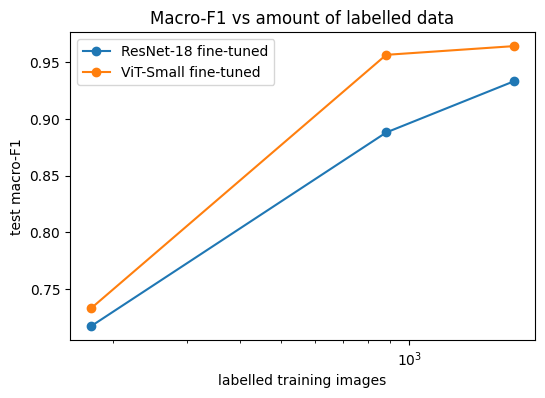

In [6]:
FRACTIONS = [0.1, 0.5, 1.0]
MODELS = {  # name: (constructor, learning rate, normalisation)
    "ResNet-18 fine-tuned": (make_resnet18, 3e-4, "imagenet"),
    "ViT-Small fine-tuned": (make_vit, 5e-5, "tanh"),
}
rows, trained = [], {}
local_loaders = {norm: ws.local_test_loader(224, normalize=norm) for norm in ["imagenet", "tanh"]}
for frac in FRACTIONS:
    for name, (ctor, lr, norm) in MODELS.items():
        ws.seed_everything()
        model = ctor()
        train_dl, val_dl, test_dl = ws.make_loaders(img_size=224, batch_size=32, train_fraction=frac, normalize=norm)
        n_img = len(train_dl.dataset)
        print(f"\n=== {name} | {int(frac * 100)}% of the training data ({n_img} images) ===")
        minutes = ws.train_classifier(model, train_dl, val_dl, n_epochs=ws.epochs(8), lr=lr)
        test = ws.evaluate(model, test_dl)
        local_dl = local_loaders[norm]
        local = ws.evaluate(model, local_dl) if local_dl else None
        ws.log_result(4, name, test, local, train_fraction=frac, params_millions=ws.count_params(model),
                      train_minutes=minutes, notes=f"{n_img} training images")
        rows.append({"model": name, "fraction": frac, "images": n_img, "accuracy": test["accuracy"],
                     "macro_f1": test["macro_f1"], "trash_f1": test["trash_f1"],
                     "local_acc": local["accuracy"] if local else np.nan,
                     "minutes": minutes, "params_M": ws.count_params(model)})
        trained[(name, frac)] = model
res = pd.DataFrame(rows)
print(res.round(3))

fig, ax = plt.subplots(figsize=(6, 4))
for name, g in res.groupby("model"):
    ax.plot(g.images, g.macro_f1, marker="o", label=name)
ax.set_xlabel("labelled training images"); ax.set_ylabel("test macro-F1"); ax.set_xscale("log")
ax.set_title("Macro-F1 vs amount of labelled data"); ax.legend()
ws.save_figure(fig, "vit_vs_resnet_data.png"); plt.show()

## Part C · Where does the ViT look?
We record the attention weights of the **last** transformer block with a forward hook, then look at how much
the [CLS] token attends to each of the 196 patches.

**TODO 3.** `attn` has shape (batch, heads, 197, 197). Take the row for the [CLS] token (index 0), drop the
[CLS] column, average over heads, and reshape to a 14 × 14 grid, one map per image.

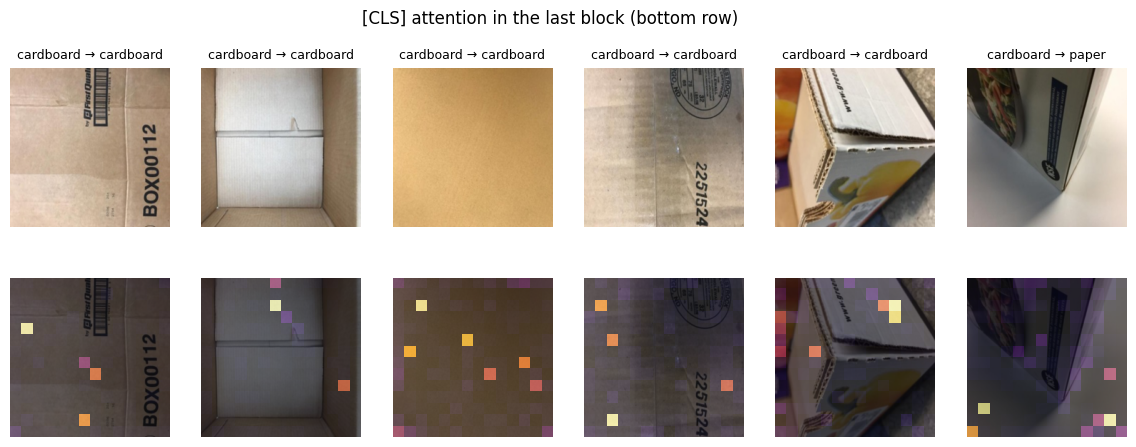

In [7]:
vit_full = trained[("ViT-Small fine-tuned", 1.0)].eval()
captured = {}
last = vit_full.blocks[-1].attn
last.fused_attn = False                      # use the explicit softmax(QK^T/sqrt(d)) path so we can read it
hook = last.attn_drop.register_forward_hook(lambda m, i, o: captured.__setitem__("attn", o.detach()))

_, _, test_dl = ws.make_loaders(img_size=224, batch_size=6, normalize="tanh")
x, y = next(iter(test_dl))
with torch.no_grad():
    pred = vit_full(x.to(dev)).argmax(1).cpu()
hook.remove()
attn = captured["attn"].cpu()
cls_attn = attn[:, :, 0, 1:]                                   # CLS row, drop the CLS column: (batch, heads, 196)
cls_maps = cls_attn.mean(dim=1).reshape(-1, 14, 14).numpy()    # average over heads, 14x14 grid per image

fig, axes = plt.subplots(2, len(x), figsize=(2.4 * len(x), 5))
for i in range(len(x)):
    img = (x[i] * 0.5 + 0.5).clamp(0, 1).permute(1, 2, 0)
    axes[0, i].imshow(img); axes[0, i].set_title(f"{ws.CLASSES[y[i]]} → {ws.CLASSES[pred[i]]}", fontsize=9)
    axes[1, i].imshow(img); axes[1, i].imshow(cls_maps[i], cmap="inferno", alpha=0.6, extent=(0, 224, 224, 0))
    axes[0, i].axis("off"); axes[1, i].axis("off")
plt.suptitle("[CLS] attention in the last block (bottom row)"); ws.save_figure(fig, "vit_attention.png"); plt.show()



 Stretch

Train a tiny ViT **from scratch** (`timm.create_model("vit_tiny_patch16_224", pretrained=False, num_classes=6)`)
for 20 epochs and compare it with your small CNN from week 1. What does this say about inductive bias?


In [11]:
ws.seed_everything()
vit_tiny = timm.create_model("vit_tiny_patch16_224", pretrained=False, num_classes=len(ws.CLASSES))
tr, va, te = ws.make_loaders(img_size=224, batch_size=32, normalize="tanh")
minutes = ws.train_classifier(vit_tiny, tr, va, n_epochs=ws.epochs(20), lr=5e-4)
test_t = ws.evaluate(vit_tiny, te)
local_t = ws.evaluate(vit_tiny, local_loaders["tanh"]) if local_loaders["tanh"] else None
print(f"ViT-Tiny from scratch: acc {test_t['accuracy']:.3f}  macro-F1 {test_t['macro_f1']:.3f}  "
      f"trash F1 {test_t['trash_f1']:.3f}  params {ws.count_params(vit_tiny):.2f} M  {minutes:.1f} min")
ws.log_result(4, "ViT-Tiny from scratch", test_t, local_t, params_millions=ws.count_params(vit_tiny),
              train_minutes=minutes, notes="no pretraining, 20 epochs, lr 5e-4")

epoch 1/20  train loss 1.585  val acc 0.385  val macro-F1 0.316
epoch 2/20  train loss 1.480  val acc 0.404  val macro-F1 0.332
epoch 3/20  train loss 1.420  val acc 0.404  val macro-F1 0.314
epoch 4/20  train loss 1.368  val acc 0.443  val macro-F1 0.352
epoch 5/20  train loss 1.284  val acc 0.441  val macro-F1 0.373
epoch 6/20  train loss 1.208  val acc 0.496  val macro-F1 0.471
epoch 7/20  train loss 1.172  val acc 0.557  val macro-F1 0.483
epoch 8/20  train loss 1.076  val acc 0.604  val macro-F1 0.542
epoch 9/20  train loss 1.058  val acc 0.620  val macro-F1 0.557
epoch 10/20  train loss 0.969  val acc 0.546  val macro-F1 0.474
epoch 11/20  train loss 0.950  val acc 0.660  val macro-F1 0.603
epoch 12/20  train loss 0.840  val acc 0.615  val macro-F1 0.570
epoch 13/20  train loss 0.829  val acc 0.665  val macro-F1 0.632
epoch 14/20  train loss 0.765  val acc 0.668  val macro-F1 0.637
epoch 15/20  train loss 0.699  val acc 0.636  val macro-F1 0.570
epoch 16/20  train loss 0.631  val

Misclassified Test Images



misclassified test indices: [ 5 48] | total errors: 12


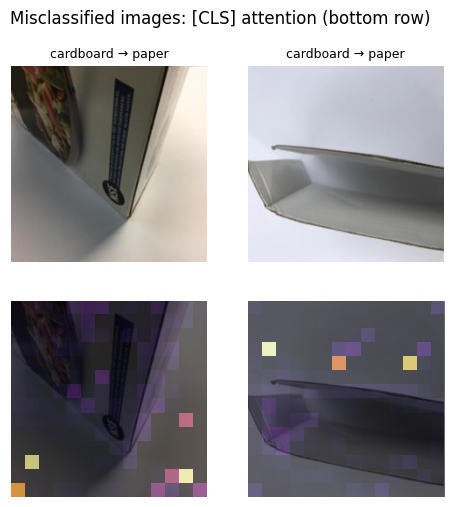

In [8]:
from PIL import Image
test_dl2 = ws.make_loaders(img_size=224, batch_size=32, normalize="tanh")[2]
m = ws.evaluate(vit_full, test_dl2)
y_true, y_pred = np.array(m["y_true"]), np.array(m["y_pred"])
wrong = np.where(y_true != y_pred)[0][:2]
print("misclassified test indices:", wrong, "| total errors:", int((y_true != y_pred).sum()))

split = ws.load_split()
test_paths = split[split.split == "test"].path.tolist()
tf = ws.transforms_for(224, False, "tanh")
xw = torch.stack([tf(Image.open(test_paths[i]).convert("RGB")) for i in wrong])

captured = {}
hook = last.attn_drop.register_forward_hook(lambda mod, i, o: captured.__setitem__("attn", o.detach()))
with torch.no_grad():
    pw = vit_full(xw.to(dev)).argmax(1).cpu()
hook.remove()
maps = captured["attn"].cpu()[:, :, 0, 1:].mean(1).reshape(-1, 14, 14).numpy()

fig, axes = plt.subplots(2, len(wrong), figsize=(2.8 * len(wrong), 5.6))
for j in range(len(wrong)):
    img = (xw[j] * 0.5 + 0.5).clamp(0, 1).permute(1, 2, 0)
    axes[0, j].imshow(img); axes[0, j].set_title(f"{ws.CLASSES[y_true[wrong[j]]]} → {ws.CLASSES[pw[j]]}", fontsize=9)
    axes[1, j].imshow(img); axes[1, j].imshow(maps[j], cmap="inferno", alpha=0.6, extent=(0, 224, 224, 0))
    axes[0, j].axis("off"); axes[1, j].axis("off")
plt.suptitle("Misclassified images: [CLS] attention (bottom row)")
ws.save_figure(fig, "vit_attention_errors.png"); plt.show()

In [9]:
from collections import Counter
bad = y_true != y_pred
pairs = Counter((ws.CLASSES[t], ws.CLASSES[p]) for t, p in zip(y_true[bad], y_pred[bad]))
for (t, p), n in pairs.most_common():
    print(f"{t} → {p}: {n}")

cardboard → paper: 3
trash → paper: 2
glass → metal: 1
glass → plastic: 1
paper → plastic: 1
paper → trash: 1
paper → cardboard: 1
plastic → metal: 1
plastic → glass: 1


## Week 4 findings

**1. Which model wins at 10% of the data, and which at 100%? Does this match the lecture's claim about inductive bias?**

| Training data | ResNet-18 acc / macro-F1 / trash F1 | ViT-Small acc / macro-F1 / trash F1 |
|---|---|---|
| 10% (178 images) | 0.755 / 0.717 / 0.452 | 0.821 / 0.733 / 0.160 |
| 50% (883 images) | 0.902 / 0.888 / 0.800 | 0.960 / 0.956 / 0.923 |
| 100% (1,766 images) | 0.939 / 0.933 / 0.884 | 0.968 / 0.964 / 0.927 |

At 10% of the data, the ViT has higher accuracy (0.821 vs 0.755) and slightly higher macro-F1 (0.733 vs 0.717), but a much worse trash F1 (0.160 vs 0.452). Trash has only about 10 training images at 10%, and the test set has 21 trash images, so I cannot call a clear winner. At 100%, the ViT wins on macro-F1 (0.964 vs 0.933). The ViT was at or above ResNet-18 at every data size, so the lecture's claim that ViTs suffer more when data is scarce did not show up. This is probably because both models were pretrained: the ViT did not have to learn locality from scratch, and the claim applies mainly to training from scratch. Each result is a single run on 379 test images, so small gaps (especially at 10%) may be noise.

**2. Both models were pretrained. Which pretraining data did each use, and how might that affect the comparison?**

ResNet-18 used the default torchvision ImageNet weights, trained on ImageNet-1k (about 1.3 million images, 1,000 classes). The ViT name, `augreg_in21k_ft_in1k`, means it was pretrained on the larger ImageNet-21k and then fine-tuned on ImageNet-1k with strong augmentation and regularisation. The ViT therefore saw more pretraining data, which probably explains part of its advantage. The comparison is also not fully controlled: the two models used different learning rates (3e-4 for ResNet-18, 5e-5 for the ViT) and different input normalisation, as they were pretrained differently. The ViT has about twice the parameters of ResNet-18, which is another difference besides architecture.

**3. Does attention land on the object or on the background? What do the mistakes have in common?**

The [CLS] attention of the last block was sparse in the images I looked at: a few bright patches, often on plain areas, instead of a blob over the object. The ViT made 12 errors on the 379 test images. I examined the first two, and both were cardboard predicted as paper: a box corner against a smooth white surface, and a thin cardboard flap seen at an angle against a plain white background. In both, the object showed no visible corrugation and much of the attention fell on the background and edges. What the mistakes have in common is a plain white background, smooth low-texture surfaces and unusual viewpoints. The model may rely on background and context, and it may confuse cardboard and paper when texture is not visible. This is the same cardboard/paper confusion that ResNet-18 showed in week 1. Two limits: the test set is ordered by class, so these are the first two of 12 errors and may not be representative, and attention maps from one block averaged over heads are only a hint about what the model uses.

**4. Compare parameter counts and training time. Which would you deploy on a small device at a sorting line?**

| | Parameters | Training time, 100% data, 8 epochs (T4) |
|---|---|---|
| ResNet-18 | 11.2 M | 1.0 min |
|